In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
from pathlib import Path
# Procura a raiz do projeto (pasta que contém `src`) subindo na arvore
def find_project_root(start: Path = Path.cwd()) -> Path:
    for p in [start] + list(start.parents):
        if (p / 'src').is_dir():
            return p
    return start
proj_root = str(find_project_root())
if proj_root not in sys.path:
    sys.path.insert(0, proj_root)
print('Project root added to sys.path:', proj_root)

from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import LabelBinarizer, LabelEncoder
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, cross_val_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from src.preprocessing import SavgolFilter, SNV, make_savgol, make_scaler, make_snv
from src.utils import extrair_numero
from src.models import PLSDAClassifier, PLSDAMulticlass

from src.config import *

list_dirs()


Project root added to sys.path: c:\Users\Pedro\Downloads\LIBS_NEW
BASE_DIR:  C:\Users\Pedro\Downloads\LIBS_NEW 
DATA_DIR:  C:\Users\Pedro\Downloads\LIBS_NEW\dataset 
MODELS_DIR:  C:\Users\Pedro\Downloads\LIBS_NEW\models 
PLOTS_DIR: C:\Users\Pedro\Downloads\LIBS_NEW\plots


C:\Users\Pedro\AppData\Local\Temp\ipykernel_15472\645030261.py:16: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,

Desenvolvimento: (1717, 12288) (81.1%)
Teste final: (400, 12288) (18.9%)
Grupos no teste: ['Do_Ponto_sample' 'Mio_do_PR_1_04pc' 'Pilao_sample' 'R4_sample']

Ranking do CV:
snv_scaler_svm_linear: 0.9859
snv_svm_linear: 0.8911

Melhor modelo: snv_scaler_svm_linear
Acurácia no teste final de 20%: 1.0000


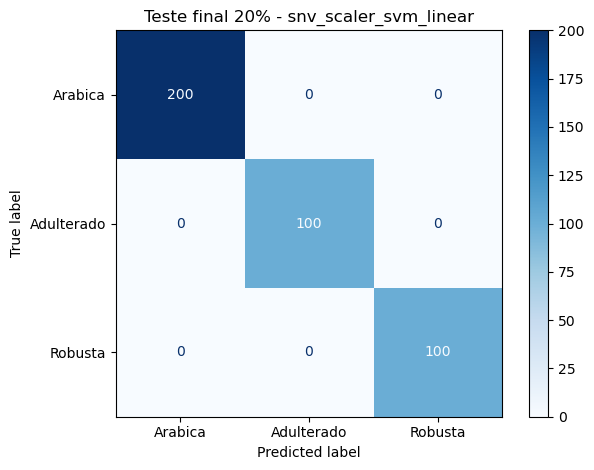

Modelo final salvo em: C:\Users\Pedro\Downloads\LIBS_NEW\temp\models_groupkfold\laser266\snv_scaler_svm_linear_final_80pct.joblib


In [ ]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedGroupKFold

from src.training import build_pipeline, run_experiment
from src.config import *


# Configuração
laser = 266
file_path = Path(proj_root) / 'dataset/merged_output.dat'


# Carrega os dados
df = pd.read_csv(file_path, sep=';', header=None)

y_raw = df.iloc[0, 1:].values.astype(str)
X_full = df.iloc[1:, 1:].values.astype(float).T


# Define os rótulos
extra_a_labels_266 = {
    'Pilao_sample',
    'Evolutto_sample',
    'Do_Ponto_sample',
    'America_sample',
    'Coamo_sample',
}

labels_adulterados = {
    'Terra_da_Gente_11pc',
    'Jangadinha_1_63pc',
    'Gosto_bom_1_6pc',
    'Mio_do_PR_1_04pc',
    'Balaio_1_1pc',
    'Forte_1_4pc',
}


# Organiza os dados e grupos
X, y, groups = [], [], []

for xi, yi in zip(X_full, y_raw):
    if yi in labels_adulterados:
        X.append(xi)
        y.append('C')
        groups.append(yi)

    elif yi.startswith('A') or yi in extra_a_labels_266:
        X.append(xi)
        y.append('A')
        groups.append(yi)

    elif yi.startswith('R'):
        X.append(xi)
        y.append('R')
        groups.append(yi)

X = np.array(X)
y = np.array(y)
groups = np.array(groups)


# Separa desenvolvimento e teste
holdout = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=1,
)

dev_idx, test_idx = next(
    holdout.split(X, y, groups)
)

X_dev, X_test = X[dev_idx], X[test_idx]
y_dev, y_test = y[dev_idx], y[test_idx]
groups_dev, groups_test = groups[dev_idx], groups[test_idx]


# Valida a separação
if set(groups_dev) & set(groups_test):
    raise ValueError(
        'Um grupo foi dividido entre desenvolvimento e teste.'
    )

if set(np.unique(y_test)) != set(np.unique(y)):
    raise ValueError(
        'O teste final não contém as três classes.'
    )

print(
    f'Desenvolvimento: {X_dev.shape} '
    f'({len(X_dev) / len(X):.1%})'
)

print(
    f'Teste final: {X_test.shape} '
    f'({len(X_test) / len(X):.1%})'
)

print(f'Grupos no teste: {np.unique(groups_test)}')


# Cross-validation
sgkf = StratifiedGroupKFold(
    n_splits=min(4, len(np.unique(groups_dev))),
    shuffle=True,
    random_state=RANDOM_SEED,
)


# Pré-processamentos e modelos
preprocessamentos = {
    'snv': [make_snv()],
    'snv_scaler': [make_snv(), make_scaler()],
}

modelos = {
    'svm_linear': SVC(
        kernel='linear',
        gamma='scale',
    ),
}


# Diretórios de saída
output_models = f'{BASE_DIR}/temp/models_groupkfold/laser{laser}'
output_plots = f'{BASE_DIR}/temp/plots_groupkfold/laser{laser}'

os.makedirs(output_models, exist_ok=True)
os.makedirs(output_plots, exist_ok=True)


# Executa os experimentos
results_data = run_experiment(
    X=X_dev,
    y=y_dev,
    preprocessamentos=preprocessamentos,
    modelos=modelos,
    cv=sgkf,
    output_models_dir=output_models,
    output_plots_dir=output_plots,
    laser=laser,
    labels=np.array(['A', 'C', 'R']),
    experiment_name='stratified_groupkfold_266_3classes_adulterantes_dev80',
    display_labels=['Arabica', 'Adulterado', 'Robusta'],
    groups=groups_dev,
    summary_filename='all_pipelines_summary_266_3classes_adulterantes_dev80.json',
    ranking_filename='ranking_final_groupkfold_266_3classes_adulterantes_dev80.png',
)

results = results_data['results']


# Seleciona o melhor modelo
best_name = max(results, key=results.get)

prep_name, model_name = next(
    (p, m)
    for p in preprocessamentos
    for m in modelos
    if f'{p}_{m}' == best_name
)


# Treina e testa o vencedor
best_pipeline = build_pipeline(
    preprocessamentos[prep_name],
    clone(modelos[model_name]),
)

best_pipeline.fit(X_dev, y_dev)

y_pred = best_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)


# Exibe os resultados
print('\nRanking do CV:')

for name, score in sorted(
    results.items(),
    key=lambda item: item[1],
    reverse=True,
):
    print(f'{name}: {score:.4f}')

print(f'\nMelhor modelo: {best_name}')
print(f'Acurácia no teste final de 20%: {accuracy:.4f}')


# Matriz de confusão
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['A', 'C', 'R'],
)

ConfusionMatrixDisplay(
    cm,
    display_labels=['Arabica', 'Adulterado', 'Robusta'],
).plot(
    cmap='Blues',
    values_format='d',
)

plt.title(f'Teste final 20% - {best_name}')
plt.tight_layout()

plt.savefig(
    Path(output_plots) / f'{best_name}_final_test_cm.png',
    dpi=150,
)

plt.show()
plt.close()


# Salva o modelo final
final_model_path = (
    Path(output_models) / f'{best_name}_final_80pct.joblib'
)

joblib.dump(best_pipeline, final_model_path)

print(f'Modelo final salvo em: {final_model_path}')


C:\Users\Pedro\AppData\Local\Temp\ipykernel_15472\3488226622.py:26: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254

Desenvolvimento: (1700, 12288) (80.3%)
Teste final: (417, 12288) (19.7%)
Grupos no teste: ['Do_Ponto_sample' 'Mio_do_PR_1_04pc' 'R7_sample' 'Terra_da_Gente_11pc']

Ranking do CV:
snv_scaler_svm_linear: 0.9981
snv_svm_linear: 0.9594

Melhor modelo: snv_scaler_svm_linear
Acurácia no teste final de 20%: 0.9952


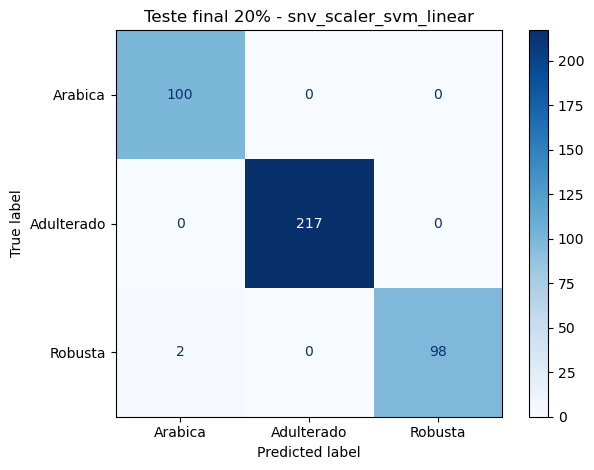

Modelo final salvo em: C:\Users\Pedro\Downloads\LIBS_NEW\temp\models_groupkfold\laser266\snv_scaler_svm_linear_final_80pct.joblib


In [10]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedGroupKFold

from src.training import build_pipeline, run_experiment
from src.config import *


# Configuração
laser = 266
file_path = Path(proj_root) / 'dataset/merged_output.dat'


# Carrega os dados
df = pd.read_csv(file_path, sep=';', header=None)

y_raw = df.iloc[0, 1:].values.astype(str)
X_full = df.iloc[1:, 1:].values.astype(float).T


# Define os rótulos
extra_a_labels_266 = {
    'Pilao_sample',
    'Evolutto_sample',
    'Do_Ponto_sample',
    'America_sample',
    'Coamo_sample',
}

labels_adulterados = {
    'Terra_da_Gente_11pc',
    'Jangadinha_1_63pc',
    'Gosto_bom_1_6pc',
    'Mio_do_PR_1_04pc',
    'Balaio_1_1pc',
    'Forte_1_4pc',
}


# Organiza os dados e grupos
X, y, groups = [], [], []

for xi, yi in zip(X_full, y_raw):
    if yi in labels_adulterados:
        X.append(xi)
        y.append('C')
        groups.append(yi)

    elif yi.startswith('A') or yi in extra_a_labels_266:
        X.append(xi)
        y.append('A')
        groups.append(yi)

    elif yi.startswith('R'):
        X.append(xi)
        y.append('R')
        groups.append(yi)

X = np.array(X)
y = np.array(y)
groups = np.array(groups)


# Separa desenvolvimento e teste
holdout = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=2,
)

dev_idx, test_idx = next(
    holdout.split(X, y, groups)
)

X_dev, X_test = X[dev_idx], X[test_idx]
y_dev, y_test = y[dev_idx], y[test_idx]
groups_dev, groups_test = groups[dev_idx], groups[test_idx]


# Valida a separação
if set(groups_dev) & set(groups_test):
    raise ValueError(
        'Um grupo foi dividido entre desenvolvimento e teste.'
    )

if set(np.unique(y_test)) != set(np.unique(y)):
    raise ValueError(
        'O teste final não contém as três classes.'
    )

print(
    f'Desenvolvimento: {X_dev.shape} '
    f'({len(X_dev) / len(X):.1%})'
)

print(
    f'Teste final: {X_test.shape} '
    f'({len(X_test) / len(X):.1%})'
)

print(f'Grupos no teste: {np.unique(groups_test)}')


# Cross-validation
sgkf = StratifiedGroupKFold(
    n_splits=min(4, len(np.unique(groups_dev))),
    shuffle=True,
    random_state=RANDOM_SEED,
)


# Pré-processamentos e modelos
preprocessamentos = {
    'snv': [make_snv()],
    'snv_scaler': [make_snv(), make_scaler()],
}

modelos = {
    'svm_linear': SVC(
        kernel='linear',
        gamma='scale',
    ),
}


# Diretórios de saída
output_models = f'{BASE_DIR}/temp/models_groupkfold/laser{laser}'
output_plots = f'{BASE_DIR}/temp/plots_groupkfold/laser{laser}'

os.makedirs(output_models, exist_ok=True)
os.makedirs(output_plots, exist_ok=True)


# Executa os experimentos
results_data = run_experiment(
    X=X_dev,
    y=y_dev,
    preprocessamentos=preprocessamentos,
    modelos=modelos,
    cv=sgkf,
    output_models_dir=output_models,
    output_plots_dir=output_plots,
    laser=laser,
    labels=np.array(['A', 'C', 'R']),
    experiment_name='stratified_groupkfold_266_3classes_adulterantes_dev80',
    display_labels=['Arabica', 'Adulterado', 'Robusta'],
    groups=groups_dev,
    summary_filename='all_pipelines_summary_266_3classes_adulterantes_dev80.json',
    ranking_filename='ranking_final_groupkfold_266_3classes_adulterantes_dev80.png',
)

results = results_data['results']


# Seleciona o melhor modelo
best_name = max(results, key=results.get)

prep_name, model_name = next(
    (p, m)
    for p in preprocessamentos
    for m in modelos
    if f'{p}_{m}' == best_name
)


# Treina e testa o vencedor
best_pipeline = build_pipeline(
    preprocessamentos[prep_name],
    clone(modelos[model_name]),
)

best_pipeline.fit(X_dev, y_dev)

y_pred = best_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)


# Exibe os resultados
print('\nRanking do CV:')

for name, score in sorted(
    results.items(),
    key=lambda item: item[1],
    reverse=True,
):
    print(f'{name}: {score:.4f}')

print(f'\nMelhor modelo: {best_name}')
print(f'Acurácia no teste final de 20%: {accuracy:.4f}')


# Matriz de confusão
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['A', 'C', 'R'],
)

ConfusionMatrixDisplay(
    cm,
    display_labels=['Arabica', 'Adulterado', 'Robusta'],
).plot(
    cmap='Blues',
    values_format='d',
)

plt.title(f'Teste final 20% - {best_name}')
plt.tight_layout()

plt.savefig(
    Path(output_plots) / f'{best_name}_final_test_cm.png',
    dpi=150,
)

plt.show()
plt.close()


# Salva o modelo final
final_model_path = (
    Path(output_models) / f'{best_name}_final_80pct.joblib'
)

joblib.dump(best_pipeline, final_model_path)

print(f'Modelo final salvo em: {final_model_path}')
